# Verifying LLM answers against their source

<a href="https://colab.research.google.com/github/sixhobbits/colab-demo/blob/main/cookbooks/verify_llm_outputs/verify_llm_outputs.ipynb" target="_blank"><img src="https://img.shields.io/badge/Open%20in%20Colab-F9AB00?style=for-the-badge&logo=googlecolab&logoColor=white" alt="Open in Colab" height="28"></a> <a href="https://github.com/sixhobbits/colab-demo/blob/main/cookbooks/verify_llm_outputs/verify_llm_outputs.ipynb" target="_blank"><img src="https://img.shields.io/badge/View%20on%20GitHub-24292F?style=for-the-badge&logo=github&logoColor=white" alt="View on GitHub" height="28"></a>

> **No API key needed.** The code downloads this cookbook's saved answers, so
> *Run all* replays every TypeSafe call from them. It needs no TypeSafe account
> and costs nothing. To call the API yourself, set `TYPESAFE_API_KEY` and
> `DOWNLOAD_CACHE = False`.

From [the docs page](https://console.typesafe.ai/docs/cookbooks/verify_llm_outputs).

You have an LLM answering questions from paragraphs you retrieved for it, and most of its
answers are right.

Two kinds of mistake are common. The LLM gives an answer the paragraphs never state,
filling a missing step with a guess. Or it says the paragraphs don't answer the question
when they do. Neither kind looks any different from a right answer.

In this cookbook we check each answer with one Jev request that asks three `Noul`
questions about the paragraphs and the answer:

- `answerable`: do the paragraphs state every fact the question needs?
- `declines`: does the answer decline, saying the paragraphs don't have the answer?
- `supported`: start from the question and follow the paragraphs step by step. Do you
  arrive at the LLM's answer?

A few lines of code turn those three into one risk number, where higher means the answer is
more likely wrong. If the LLM declined, the risk is the chance the paragraphs do answer the
question. If it answered, the risk is the chance the paragraphs don't lead to its answer.
An answer with a risk of 0.2 or more goes to review.

We ran this on 1,000 questions answered by `gpt-6-luna`. Each question takes two to four
steps to answer, with earlier answers needed for later steps. 88.5% of the answers were
right. The check passed 73% of the answers, and 95.7% of those were right. The other 27%
went to review, and they included 84 of the 115 wrong answers.

<img src="https://raw.githubusercontent.com/sixhobbits/colab-demo/main/cookbooks/verify_llm_outputs/verify_llm_outputs-diagram-39e7bf1a58.png" alt="Diagram" width="1176">

You end up with `check_answer()`. It takes a question, its paragraphs and an answer, and
returns the three probabilities, the risk, and `pass` or `review`.

## Setup

```bash
pip install openai ipython matplotlib 'cooksafe>=0.3.0,<0.4.0'
```

then set `TYPESAFE_API_KEY` and `OPENAI_API_KEY`. OpenAI models write the answers being
checked. In the measurement at the end, an OpenAI model also decides whether an answer is
right when it doesn't match the dataset's reference answer.

The numbers below came from `jev-1.14.0` on 2026-11-07, checking answers that `gpt-6-luna`
wrote the same day.

In [ ]:
%pip install -q 'openai' 'typesafe-sdk>=0.7.0' 'ipython' 'matplotlib' 'cooksafe>=0.3.0,<0.4.0'

In [ ]:
import json
import os
import urllib.request
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from cooksafe import JsonCache, make_playground_link
from IPython.display import Markdown, display
from openai import OpenAI
from typesafe_sdk import Noul, NoulCriteria, TypeSafeClient

TYPESAFE_MODEL = "jev-1.14.0"  # the page's model; "jev-latest" runs the newest, live
ANSWERING_MODEL = "gpt-6-luna"  # the LLM whose answers are checked
RECHECK_MODEL = "gpt-6.1-sol"  # settles answers that disagree with the reference, for measuring
REVIEW_AT = 0.2  # a risk at or above this sends the answer to review
LLM_WORKERS = 8  # about 1,250 OpenAI calls
TYPESAFE_WORKERS = 4  # 2,000 Jev calls; more workers hits the public rate limit

client = TypeSafeClient(
    api_key=os.environ.get("TYPESAFE_API_KEY", "cache-only"),  # keyless kernels replay the cache
    base_url=os.environ.get("TYPESAFE_ENDPOINT"),
    timeout=120.0,
)
llm = OpenAI(api_key=os.environ.get("OPENAI_API_KEY", "cache-only"))

EXAMPLES = (
    "https://raw.githubusercontent.com/typesafe-ai/typesafe-public-examples/main/"
    "cookbooks/verify_llm_outputs"
)


def download(name: str) -> Path:
    """Fetch one of this cookbook's files from typesafe-public-examples unless it is on disk."""
    path = Path(name)
    if not path.exists():
        urllib.request.urlretrieve(f"{EXAMPLES}/{name}", path)
    return path


CACHE = Path("verify_llm_outputs_cache.json")
# True fills CACHE with the published answers, so the run makes no requests. To run
# live, set it to False and delete CACHE; a CACHE already on disk is never overwritten.
DOWNLOAD_CACHE = True
if DOWNLOAD_CACHE:
    download(CACHE.name)
json_cache = JsonCache(CACHE, indent=None)

## Load the questions and their paragraphs

The questions come from [MuSiQue](https://github.com/StonyBrookNLP/musique) (Trivedi et
al., CC BY 4.0). Each one joins two to four simple questions about Wikipedia into one, so
the answer to an earlier part is needed to ask a later one. Each comes with 20 paragraphs.
Most of them are on nearby topics and don't help answer the question.

MuSiQue has two versions of each question. In one, the paragraphs hold every fact the
question needs. In the other, a paragraph it needs has been removed, so the question can't
be answered, though the remaining paragraphs still look as if they might. The file holds a
fixed random sample of 1,000 questions from MuSiQue's development set, with one of the two
versions of each. About half are the version that can't be answered.

In [ ]:
DATA = json.loads(download("musique_questions.json").read_text(encoding="utf-8"))
QUESTIONS = DATA["questions"]
BY_ID = {q["id"]: q for q in QUESTIONS}


def paragraphs_text(q: dict) -> str:
    return "\n\n".join(f"## {p['title']}\n{p['text']}" for p in q["paragraphs"])


answerable = sum(q["answerable"] for q in QUESTIONS)
print(f"{len(QUESTIONS):,} questions, {answerable} answerable from their paragraphs")
example = QUESTIONS[0]
print(f"\n{example['question']}")
print("paragraphs:", "; ".join(p["title"] for p in example["paragraphs"][:6]), "; ...")

1,000 questions, 473 answerable from their paragraphs

On what team was the player who hit the first home run at the new location of NY Yankees home games?
paragraphs: Yankee Stadium (1923); Yankee Stadium; Utah Jazz; New York City; List of milestone home runs by Barry Bonds; Vegas Golden Knights ; ...


## Answer them with `gpt-6-luna`

The instruction lets the model say the paragraphs don't answer the question, which is where
the refusals checked below come from. To check your own LLM, replace `answer_prompt()` and
`ask_llm()`.

In [ ]:
ANSWER_INSTRUCTION = (
    "Answer the question using only the paragraphs. Return only the shortest answer that fully "
    "answers the question. Do not explain your reasoning. If the paragraphs do not answer the "
    "question, say so."
)


def answer_prompt(q: dict) -> str:
    return (
        f"{ANSWER_INSTRUCTION}\n\nQuestion:\n{q['question']}\n\n"
        f"Paragraphs:\n{paragraphs_text(q)}"
    )


@json_cache
def ask_llm(prompt: str, answering_model: str) -> dict:
    response = llm.chat.completions.create(
        model=answering_model, messages=[{"role": "user", "content": prompt}]
    )
    return {
        "answer": (response.choices[0].message.content or "").strip(),
        "input_tokens": response.usage.prompt_tokens,
        "output_tokens": response.usage.completion_tokens,
    }


with ThreadPoolExecutor(max_workers=LLM_WORKERS) as pool:
    LLM_ANSWERS = dict(
        zip(
            BY_ID,
            (
                r["answer"]
                for r in pool.map(
                    lambda q: ask_llm(answer_prompt(q), answering_model=ANSWERING_MODEL),
                    QUESTIONS,
                )
            ),
        )
    )

print(f"{example['question']}\n  {ANSWERING_MODEL}: {LLM_ANSWERS[example['id']]}")

On what team was the player who hit the first home run at the new location of NY Yankees home games?
  gpt-6-luna: New York Yankees.


## Ask Jev three questions about each answer

Each answer gets one Jev request. Its state holds the question, the instruction the LLM was
given, the paragraphs, and the LLM's answer. The three questions go in the same request.

In [ ]:
def noul(instructions: str, yes: str, no: str) -> Noul:
    return Noul(instructions=instructions, criteria=NoulCriteria(true=yes, false=no))


CHECK_QUESTIONS = {
    "answerable": noul(
        "Do the paragraphs state every fact needed to answer the question?",
        yes="each step from the question to its answer is stated in the paragraphs",
        no="at least one step from the question to its answer is not stated in the paragraphs",
    ),
    "declines": noul(
        "Does the candidate response decline to answer, or say the information is missing?",
        yes="the candidate says it cannot answer or that the paragraphs do not say",
        no="the candidate gives an answer",
    ),
    "supported": noul(
        "Following the paragraphs step by step from the question, do you arrive at the "
        "candidate's answer?",
        yes="the paragraphs connect the question to the candidate's answer through stated facts",
        no="the paragraphs do not connect the question to the candidate's answer",
    ),
}


def as_json(questions: dict) -> str:
    return json.dumps(
        {k: q.model_dump(mode="json", exclude_none=True) for k, q in questions.items()},
        sort_keys=True,
    )


def check_state(question: str, paragraphs: str, answer: str) -> dict:
    return {
        "request": question,
        "response_requirement": ANSWER_INSTRUCTION,
        "paragraphs": paragraphs,
        "candidate_response": answer,
    }


@json_cache
def ask_jev(
    question: str, paragraphs: str, answer: str, questions_json: str, model: str
) -> dict:
    response = client.system_one(
        check_state(question, paragraphs, answer), json.loads(questions_json), model=model
    )
    return {
        "nouls": {k: response.answers[k].noul for k in sorted(response.answers)},
        "input_tokens": response.usage.input_tokens or 0,
    }


def check_answer(question: str, paragraphs: str, answer: str) -> dict:
    nouls = ask_jev(
        question, paragraphs, answer, as_json(CHECK_QUESTIONS), model=TYPESAFE_MODEL
    )["nouls"]
    if nouls["declines"] >= 0.5:
        risk = nouls["answerable"]  # it declined: risky if the paragraphs do answer
    else:
        risk = 1 - nouls["supported"]  # it answered: risky if the paragraphs don't lead there
    return {**nouls, "risk": risk, "status": "review" if risk >= REVIEW_AT else "pass"}


with ThreadPoolExecutor(max_workers=TYPESAFE_WORKERS) as pool:
    CHECKS = dict(
        zip(
            BY_ID,
            pool.map(
                lambda q: check_answer(q["question"], paragraphs_text(q), LLM_ANSWERS[q["id"]]),
                QUESTIONS,
            ),
        )
    )

## See how the check scores four answers

The check passes the first two and sends the last two to review. In order: a right answer,
a right refusal, an answer the paragraphs don't support, and a refusal of a question the
paragraphs do answer.

In [ ]:
def show(question_id: str) -> None:
    q, check = BY_ID[question_id], CHECKS[question_id]
    print(q["question"])
    print(f"  {ANSWERING_MODEL}: {LLM_ANSWERS[question_id]}")
    print(
        f"  answerable {check['answerable']:.2f}  declines {check['declines']:.2f}  "
        f"supported {check['supported']:.2f}  ->  risk {check['risk']:.2f}, "
        f"{check['status'].upper()}\n"
    )


DEMOS = [
    "2hop__501624_181960__ans",  # The Mud Bath
    "2hop__728887_159109__unans",  # Assomada
    "2hop__145082_35034__unans",  # Tammy Leitner
    "2hop__580231_162399__ans",  # Dahyabhai Patel
]
for question_id in DEMOS:
    show(question_id)

Where did the painter of The Mud Bath study?
  gpt-6-luna: The Slade School of Art.
  answerable 0.97  declines 0.02  supported 0.98  ->  risk 0.02, PASS

Where is Assomada located?
  gpt-6-luna: The paragraphs do not say where Assomada is located.
  answerable 0.07  declines 0.99  supported 0.97  ->  risk 0.07, PASS

What was the population density of Tammy Leitner's city of birth in 2009?
  gpt-6-luna: 182.5/km²
  answerable 0.12  declines 0.04  supported 0.08  ->  risk 0.92, REVIEW

When did the father of Dahyabhai Patel die?
  gpt-6-luna: The paragraphs do not say when Dahyabhai Patel’s father died.
  answerable 0.86  declines 0.81  supported 0.09  ->  risk 0.86, REVIEW


The first two pass for opposite reasons. The Mud Bath answer gets `supported` at 0.98, so
the paragraphs lead to it. The Assomada answer declines, and `answerable` is 0.07, so
declining was right.

Tammy Leitner was born in San Diego, but no paragraph gives San Diego's population density
in 2009. So `supported` is 0.08 and the risk is 0.92. The Patel question can be answered:
one paragraph names Sardar Vallabhbhai Patel as Dahyabhai Patel's father, and another gives
the date he died. The LLM declined anyway. With `answerable` at 0.86, the refusal goes to
review.

## Label every answer

To measure the check, every answer needs a label: right or wrong. MuSiQue gives each
question a reference answer. A separate Jev request with one `Noul` question compares the
LLM's answer with the reference. It doesn't see the paragraphs, and it accepts the same
answer in different words. An answer that matches counts as right. One that doesn't goes to
`gpt-6.1-sol`, which reads the paragraphs and labels the answer right, wrong or unclear.
That second step is there because the reference is sometimes wrong about the paragraphs.

In [ ]:
REFERENCE_QUESTIONS = {
    "matches_reference": noul(
        "Does the candidate response give the same answer as the reference answer?",
        yes=(
            "the candidate names the same entity, value or date as one of the reference "
            "answers, allowing for different wording; or the reference says the question "
            "cannot be answered and the candidate declines to answer"
        ),
        no=(
            "the candidate names something different from every reference answer; or it "
            "declines when the reference gives an answer; or it gives an answer when the "
            "reference says the question cannot be answered"
        ),
    )
}


def reference_state(q: dict, answer: str) -> dict:
    if q["answerable"]:
        reference = {"reference_answer": q["answer"], "also_accepted": q["answer_aliases"]}
    else:
        reference = {"reference_answer": "The question cannot be answered from the source."}
    return {"question": q["question"], **reference, "candidate_response": answer}


@json_cache
def matches_reference(question_id: str, answer: str, questions_json: str, model: str) -> float:
    state = reference_state(BY_ID[question_id], answer)
    response = client.system_one(state, json.loads(questions_json), model=model)
    return response.answers["matches_reference"].noul


RECHECK_SCHEMA = {
    "type": "object",
    "additionalProperties": False,
    "required": ["label", "rationale"],
    "properties": {
        "label": {"type": "string", "enum": ["right", "wrong", "unclear"]},
        "rationale": {"type": "string"},
    },
}


@json_cache
def recheck(question_id: str, answer: str, recheck_model: str) -> dict:
    q = BY_ID[question_id]
    references = [q["answer"], *q["answer_aliases"]] if q["answerable"] else ["(none)"]
    prompt = (
        "Grade one answer to a question about the paragraphs below. The reference answers "
        "were written by people and may be wrong about what the paragraphs say. Label it "
        "right if it is correct and complete according to the paragraphs, including a "
        "correct statement that they do not answer the question; wrong if it is not; "
        "unclear only if the paragraphs genuinely leave it open.\n\n"
        f"The answerer was told: {ANSWER_INSTRUCTION}\n\n"
        f"Question:\n{q['question']}\n\nReference answers: {'; '.join(references)}\n\n"
        f"Answer to grade:\n{answer}\n\nParagraphs:\n{paragraphs_text(q)}"
    )
    response = llm.chat.completions.create(
        model=recheck_model,
        reasoning_effort="high",
        messages=[{"role": "user", "content": prompt}],
        response_format={
            "type": "json_schema",
            "json_schema": {"name": "grade", "schema": RECHECK_SCHEMA, "strict": True},
        },
    )
    return json.loads(response.choices[0].message.content)


def label(question_id: str) -> dict:
    answer = LLM_ANSWERS[question_id]
    if matches_reference(
        question_id, answer, as_json(REFERENCE_QUESTIONS), model=TYPESAFE_MODEL
    ) >= 0.5:
        return {"label": "right", "by": "reference"}
    return {**recheck(question_id, answer, recheck_model=RECHECK_MODEL), "by": RECHECK_MODEL}


with ThreadPoolExecutor(max_workers=TYPESAFE_WORKERS) as pool:
    LABELS = dict(zip(BY_ID, pool.map(label, BY_ID)))

by_source = Counter((v["by"], v["label"]) for v in LABELS.values())
print(f"matched the reference: {by_source[('reference', 'right')]}")
for verdict in ("right", "wrong", "unclear"):
    print(f"re-checked by {RECHECK_MODEL}, {verdict}: {by_source[(RECHECK_MODEL, verdict)]}")

matched the reference: 739
re-checked by gpt-6.1-sol, right: 146
re-checked by gpt-6.1-sol, wrong: 115
re-checked by gpt-6.1-sol, unclear: 0


739 answers matched the reference. For the other 261, `gpt-6.1-sol` read the paragraphs and
found 146 of them right after all. In each of those, the reference was wrong about the
paragraphs in one of two ways. Either MuSiQue counts the question as answerable but the
paragraphs skip a step, or the question was meant to be unanswerable but another paragraph
still has its answer. That leaves 115 wrong answers.

## Measure the check on 1,000 answers

The table compares two ways of using the LLM: take every answer, or take only the answers
the check passes. The second is shown at a few thresholds, and an answer passes when its
risk is below the threshold. In each row, "how many" is the number of answers used,
"right" is the share of those that are correct, and "wrong held back" counts the LLM's
wrong answers that went to review instead.

In [ ]:
SCORED = [qid for qid in BY_ID if LABELS[qid]["label"] != "unclear"]
WRONG = [qid for qid in SCORED if LABELS[qid]["label"] == "wrong"]


def row(name: str, used: list[str]) -> str:
    right = sum(LABELS[qid]["label"] == "right" for qid in used)
    held = len(WRONG) - sum(LABELS[qid]["label"] == "wrong" for qid in used)
    return (
        f"| {name} | {len(used):,} ({len(used) / len(SCORED):.0%}) | "
        f"{right / len(used):.1%} | {held} of {len(WRONG)} |"
    )


rows = [
    "| answers used | how many | right | wrong held back |",
    "|---|---:|---:|---:|",
    row("every answer", SCORED),
]
for threshold in (0.2, 0.3, 0.5, 0.7):
    used = [qid for qid in SCORED if CHECKS[qid]["risk"] < threshold]
    rows.append(row(f"risk below {threshold}", used))
display(Markdown("\n".join(rows)))

| answers used | how many | right | wrong held back |
|---|---:|---:|---:|
| every answer | 1,000 (100%) | 88.5% | 0 of 115 |
| risk below 0.2 | 727 (73%) | 95.7% | 84 of 115 |
| risk below 0.3 | 825 (82%) | 94.2% | 67 of 115 |
| risk below 0.5 | 917 (92%) | 91.9% | 41 of 115 |
| risk below 0.7 | 965 (96%) | 90.3% | 21 of 115 |

At 0.2 the check passes 73% of the answers, and 95.7% of those are right, compared with
88.5% across every answer. It holds back 273 answers, and 84 of them are wrong. The other
189 were right, so most of the review work goes to confirming answers that were fine.

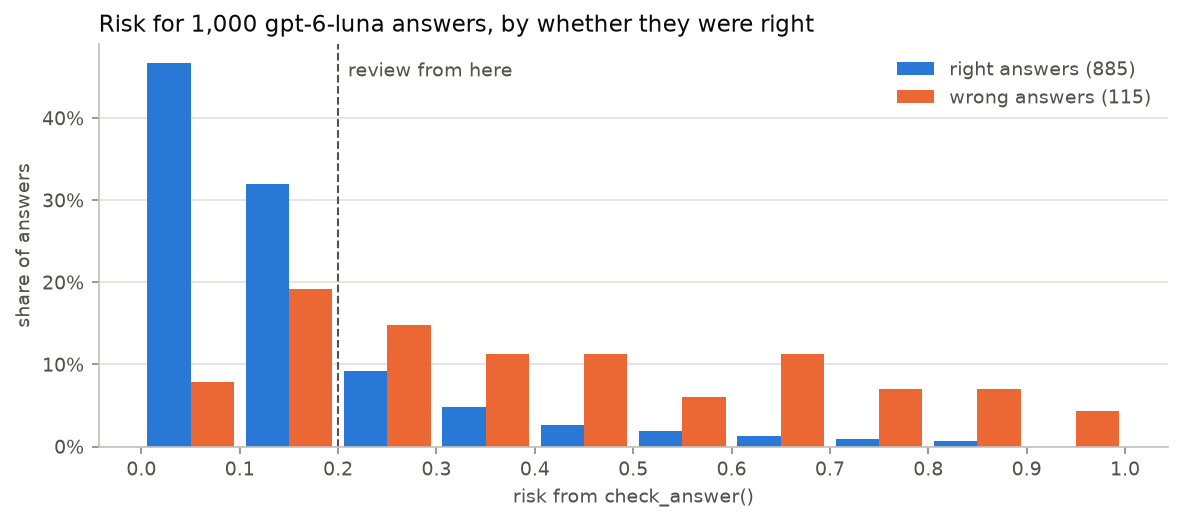

In [ ]:
# The docs page shows the chart matching its light or dark theme; a notebook shows the light one.
CHART_PALETTES = {
    "light": {
        "surface": "#ffffff", "ink": "#0b0b0b", "ink2": "#52514e", "muted": "#898781",
        "grid": "#e1e0d9", "axis": "#c3c2b7", "blue": "#2a78d6", "orange": "#eb6834",
    },
    "dark": {
        "surface": "#0d0a0f", "ink": "#fafafa", "ink2": "#d4d4d8", "muted": "#a1a1aa",
        "grid": "#2e2e33", "axis": "#52525b", "blue": "#5b9be8", "orange": "#f08050",
    },
}
BINS = [i / 10 for i in range(11)]


def draw_risk(p: dict) -> plt.Figure:
    fig, ax = plt.subplots(figsize=(8, 3.6), facecolor=p["surface"])
    ax.set_facecolor(p["surface"])
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(p["axis"])
    ax.tick_params(colors=p["muted"], labelcolor=p["ink2"], labelsize=9)
    ax.grid(axis="y", color=p["grid"], linewidth=0.8)
    ax.set_axisbelow(True)
    for verdict, colour, offset in (("right", p["blue"], -0.022), ("wrong", p["orange"], 0.022)):
        risks = [CHECKS[qid]["risk"] for qid in SCORED if LABELS[qid]["label"] == verdict]
        counts = [0] * 10
        for r in risks:
            counts[min(int(r * 10), 9)] += 1
        shares = [c / len(risks) for c in counts]
        ax.bar(
            [b + 0.05 + offset for b in BINS[:-1]], shares, width=0.044, color=colour,
            label=f"{verdict} answers ({len(risks)})",
        )
    ax.axvline(REVIEW_AT, color=p["ink2"], linewidth=1, linestyle="--")
    ax.text(REVIEW_AT + 0.01, ax.get_ylim()[1] * 0.92, "review from here", color=p["ink2"], fontsize=9)
    ax.set_xticks(BINS)
    ax.set_xlabel("risk from check_answer()", color=p["ink2"], fontsize=9)
    ax.set_ylabel("share of answers", color=p["ink2"], fontsize=9)
    ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0, decimals=0))
    ax.legend(frameon=False, labelcolor=p["ink2"], fontsize=9)
    ax.set_title(
        f"Risk for {len(SCORED):,} {ANSWERING_MODEL} answers, by whether they were right",
        loc="left", color=p["ink"], fontsize=11,
    )
    fig.tight_layout()
    return fig


for theme in ("light", "dark") if os.environ.get("COOKSAFE_RENDER") else ("light",):
    fig = draw_risk(CHART_PALETTES[theme])
    display(fig, metadata={"theme": theme})
    plt.close(fig)

Right answers are concentrated near zero risk, and wrong answers are spread across the
whole range. So the threshold has to be low to hold back most of the wrong answers, and a
threshold that low also sends some right answers to review.

## Before you use it on your own answers

- **What it misses.** 31 wrong answers passed. 18 of them answer a related question instead
  of the one asked: "Leftover Salmon" when asked who is in the band, "the NFL" when asked
  what kind of thing the NFL is. The paragraphs do lead to those answers, so `supported`
  comes back high. The other 13 are refusals of questions the paragraphs do answer. For
  those, `answerable` also came back low, 0.10 to 0.19: Jev missed the same connection
  between paragraphs that the LLM missed.
- **Set the threshold on your own answers.** The labelling step works on any set of
  questions that has reference answers. Swap in your questions, paragraphs and reference
  answers, run it again, and pick the threshold from the table.
- **What the numbers rest on.** The right and wrong labels come from models, so a stricter
  or looser re-check would change the 88.5%. We picked the three check questions over two
  other sets by trying them on the first 100 questions of this sample. Those 100 helped
  make the choice, so the results on them are not a fair test.

## Open it in the playground

The link below opens the Patel refusal in the playground, with its question, paragraphs,
answer and the three check questions filled in. Run the same request there, and edit the
questions in the browser.

In [ ]:
PLAYGROUND_ID = DEMOS[-1]
q = BY_ID[PLAYGROUND_ID]
playground_link = make_playground_link(
    check_state(q["question"], paragraphs_text(q), LLM_ANSWERS[PLAYGROUND_ID]), CHECK_QUESTIONS
)
display(Markdown(f"🔗 [Open in the TypeSafe playground]({playground_link})"))

🔗 [Open in the TypeSafe playground](https://console.typesafe.ai/playground#share/N4IgJg9gxgrgtgUwHYBcAqCAeKQC4AEIwAOiAE4ICOMCAziqQaQOoAWy+YAlmPiu-gBmAQ34Iy+CIPwARYawCewgEathXfAAVRCADacuCAPykANPlIVaABwhJaCAPoVqXColSMLIAIL2A7uJ8AtR0KFx2+DC0XEgA5pJIugrBCPjWwmTCcVnWrLQAdPgASggoMGRIicmp+LSsEGQoYfjCAUH8okIwujVttIFktLWh9BFIRTIQ+EgQKPhY1rrqVQoQFfgUwrR2sXFFAJLSYumZ2bn5nNOz8-2DIzRjdua0wik7BWbeGVk5wnm0LykADEwPwAHkUChpgBlKCsHqILj0cTEYhISHQ-BwhG6JEoiQACgAjPgfNYyFx9MSAJzEgBs+Fi+AAaoYkEhhPhAMgE+GJAAYyTA4tF5gAmfn80nMtnITkASnw-m2rSqPlFlLa+AAVutKsJdMiUOZ-A0lSqwHQoJTlAheCqTpAFBwpEL6JqqrqKpzDbQ4EUABJpZXDO1caFkAC0sUj8MM0ldMkMWisDiEZAgcD5NPppKxtIA7Iy2rxw8NrDBlL72BJBBms4XGfmaQAOGmB4MOgQiMQSV2CRqICTg4oAMXwUEaVlsSEtqC0wh62PhiIQRvEh3mIc2CAAbggDXamVUJfyacEugJ-I0ANZHgcSE4AYQOPnTmdqtPp-MKaKQf9BfB6XPGEsBSNBWD2YYxVkaYACEEAfNIAE11lkQw-2A7EwPwCCoPwGCpnwBCkPwVCYHQtJCXoBRDQALyPLDQMwcDIPiaDYOIgAWABVSjFW3LlNGWBRlAgcCWVaMAenmJAEH8P1smEOjYjSCkpCpPYFkwOYuCgfBdGgQ9aHMdYUEgRopP3VAKjoVVeFgMgKHncRdP0lBnLAX90QAsEAwgfxZAPfh8CfYRED4aYAFFMn4P9-MCmRgtYULwrSLEYqaFLkVaPkuMjOBYhgZoJ2KszVS4OBRHGIQqSzZQUgOeoKO0Zp9HU6SoCPZlC1JBragAOWquwDXwUc6uIiBMl4V0ws5MBhCKCC0kECbLQNYZ-HDFKtQOWcuC1OAFBC11rWC8ZzBLJlhhuFRdBWyyyz4SlrGsFJd2RGBRpo+7Ph89FAJZYRLUNP8gZBjQcq5RTenwD7emyNJmTgxpXl4FADRgG9hHMPwru4d09ONfAAHEYG1M5ib27hFvwA55hywyoB0e0MxgWd8BbAACm8szrD8UaGYHN2uuoKjZ2cj36k5BHEcJ7tCtQMwxiQKDiGrTT0lLljIOI9BSDqYC64ZoWUYQoEncxKS68xJyhZ4DOBlJVvicRzDQTNRAgcxNDmL37MkXtWhyPSZIqUbrQgaxClwgMfAAaRHSR-HsWoqt1SkUBSV1lGiVTaBM-B08acNs+kVq9GGTIVvrIDBQaaI0knOA4HZ0uL3mSBCs5Zphh8Vv9BheRscpfAAFlgYNDQx6pG9ZHUMgUiuiv9DNujMiKSEayL4QM4nTNW6QcNDCrih57IM2yHdtQb0acw4KyVhu6rjmn1YSkxn6IoSZLSDtQ0DIBcjz8DZnEFK4M9AaFalwJQx5577XHpkeEdRRBKD+Kwe+qNgYoKzuceQi0-y+VwgIZgnsqjMhOD4MAu4jLNAAOTDBJgFf86Jlr4FIVVchVRKHUNoQgBhpNmH4EJCTcQnCCBJjSKOLIFFKq4QNJkRUUNsxinPANRogR1ZtEjKIsgnC6hUmQJ3LIVVap4gMBQKAzReD9SoRAXQ0g0DKzogHegmRKTxCFLwKKetLSRgGsiBwSAfaLn0MULWzQJBXWkeGFx8dGgoDkmQIob5ZZVQVssfwzoJDN0KigYYtAYB6R4GkYQghIkGFoJOfcHiEgy0aHrReE5thpHqEjcsGYHCwHCJ4tQNiEAcFyeGax+B+rbyET2Gsf0WFIEAj4d+kQ5DwD-JIsaa45aIzprQLIldzCrO1AAH4JvCDgo51lNE2cyIIMIImcCCE44Gx9IiEiDGQE5VQWTiGWHEcw0i2g3kEBUW4WYJ6xHMDQ3QhxzC0hpAAZnMNYIoABWJF9JwX2MOAcaFNIaRcQRcipFBZ5SEIBmCAAMkaSQ0g4gQBqbMIYVLailAcGQfcxF-mMupgdP8bDYiLhFFkfQUhVpdQaLoS0EhtwnAfsfeooz-lBHBLQMSlQ0gwjyRgpUkEFZPgKDISYdAn5YxSlK7sbh6B032lqGldLGhLQELYGI4RIg5Ucs5FANR2DitGSkHiZB-7zBXiaM00IIBz1pUEfmWZijZARCYkou8tSRC4thawzQ4C2gkBKBk0yiGrPBIaGpWhoDbxhA0fwKzkwFq4EW32JyJBloCuaKujtmiRiPmA+Y9Qm1bRCtW2tJagjdpTj67EogCjSiqLozh2cqgxIWgoGObDh2iy5IVTAjLlhto7aweYzc7RLw5tYcQOwfSlyKDFZBygMzA2Zha206tU69pSm42ckYYDWH3ogMACh7XiFKWfPWSSDQ1BQNeCcegEDXvbiKMIMcZAVC0jLc1XaDynp9oOsgAjJlBF0dNdMVAaCoD6K9A8FAZrcIECulU0MSk3j0jeXNpLiFpCBroGgjL1H8D2DygQbGOOui42xOIBAEqRRKIa-4aQJ5kDvPMGE0BDBZwDqUS0Ls0hJTgNALIUAUjKLEmG0dMbtQLjaq0MSxVagIEnLMQq+lrTIihhzJ6iFZZWMSPvew8AT0FHps29IlZqzdRPFKfkTHZlgjkIoFQagoE6F0Cs+QShVDqFM3oYRtJ+T0m5IWWFAkuytMiK6LlWp7rA2udNTIrIQMxZS3Ftql0qhXS3UENdCAM1BFdCcbQZBDRpXnMVq1F7OoszgSjDNbw9lJZi6lle+A-jSVG1G2oZMKZZHmGyH9-xtoBwfVqa8smtIPlVMeQpWQkBdS-RkJAChGu8AcFCe6pYqjjbNr+-AAYcqrSGFuLgssyLbAaAtAwdpzBlY+r0uRkECmRDglwawsQOytqCFVJyhheBwTUEgeA1UA59NVHMbe6HSaLgxv6D7X2t0eaHrOONFrihTXtBzFrEhNBZBS5aD6Y3Mxvf8zLFwRH5hWBKRdtIroh5kAWqz+LKTdD8HWGA9IlJUdUiXqMvOckC6cJCWZn44QoDw9GxQgQABFIp8wStFwjR4W4HNtyVQpMiOw95a60i4jBZsXEuLhcBjV1QdW0sJfRGx5Y-vYv4ED8I2FpJwRWIgJmvkLYCxIp5HyFPSUuodYkLSJF-J5QIqjj0TINQbyzBHSqCXUvA8mho1UErVRbCGn1wdCYH3WniH3PaE2ZqftBQrMptnlVpOxHXH2aQJWkeCTr1aqol8P4VKum43u2vcpBIiBIMrErGUnHr-gIazqfShTsDkOgL97RCHWPtTxOGx9MoQBWKselOVWq1dMJYbwjxck31pDMCtjdN0vw8gUAEXdGFDiAVmO1iEtGPUllFwDhFBKVLHyWPGaD+APxQOmC5DbmsXMCgPv2QDnFkmGlbz2ktRpgDkrnkhrAQHMCvBVCkGaCqGZl6CPEr0yHMEQDaC0jRFIDjEQh4JADgU+32nMD9Wkjuy0BPRbyR3NhGRVH8gihniPgJE4EQ08ROEb2PmYJQIQDQJqkG3IKuh31nAgEjG0Ho1fQ0GYCq1dDdwLAKDm23CyGRGC1qEnHZiAJiEtEZSXzF2kFW0pknxozFgtlP0BX0EyWySR0KWUAcFCGI2zl1i4IcF4GPW2DaGQOW3jnYAWkwSFjAAkLgmmnsUhinXJkpjgVmCQEjA+nsSMQnBrSpEqXjzDGQEuyUliAtWlUzmRBSmM3MFtGbi0md23wEC0wtViEEHYyMQOgiIPAlWGGZACPWyCKrleggFiDkO7zSC4hpBCjZzoBF3mAMJbz32INGifGP1TFMiSOUKQwdVimdkskgysXGEWKqFpFhRTSuk+ILC1UMSV0zF0nUNN3NzIIOnHmtyMR93JUpVdBtXEHpWGC6wEGZQ7zSCKKQHDXHytV4yRk5GFHDiFUEBFQQDFS31NQxJ6LlTNixMVWVUaDkmxA1WDQBN1X1SCnqFbhvBNQK1ql713wRMqDtRY3SAgCdRqldXFiMU9T0BsV9X9XDGr1f0ikMwjVrFrhjTAXDmjUTSqGTVTXTQT2zXpCKG1BJQi3wBink3unv0oj-GtOxFtM-VWUJCURbWzRghhECAJhSlWnMX8EzkYIDm4EsRGX6h-mgz0CEi1numSWwgZgbysCMUjAXWxB9OQFwPmAHF6AChbS2F9H1zqAjCXgs1tyiDkjgCWHEiPDWHZgSGvH0U5G-QTUAENALkQkAaMRPlfAMlLGc2fPFU0AuIcAuyLEF2c-OSQKXUZQf4hWGIAeDGOSdYWgUDYQejTxZmM+V0InBjIQUQbeQkGeZYKoGQX4LgVsrgQAcEB5QYTcJph44qR9AuQx5oANy4hlA3AwA-wyUBl8B8dDILVt4tNexg1phCkST-1eBlsbdRonzNdC4YgN1nRMhhhbRSI2ki4ygPsIAGgSTWh5gKVXpYg7YUBABMAmRJJL0joA7FrAPLdlykiM6yqFNA-B8ChFDk2hVC0xBlByVHWG9W4HSnAxQoZTKQqQ0MCz0mIMZQ9nwEfNhhfLfL2E-MlzvKGl1nsTxNZCfM2TUBhwihpQgHu3Fkv24HYg8xAwvw2C8JorJHZ1ONAi5CxBOGYDCFEKzziGEEiBcqozMhNUgmQRygcB+FG36i5EpCLSujrOLKfJmAGXP1lichSCxEjgLiWmmBOAU2KhShigmO2J0oRj1kZRpwpiaw5l8rSHUSylFglzsAWiKDqtnC5H0wPGKj+yXBhn0Hhm+WDB2y5FsArC3X0OkEyDMr5FPDx2CNtFJw6v0G1X0GfQvysD3XVM-1hnVKZBQBFg2mmH0r4HAxmvavCN7PXLskXwPA8xOEJyHRKUarGuatXV0B2H-MzHSlhH0sgmxnnAAClI9WLV0lQ9B9BS8hFj0hgRom89NKNWkMYSpXRliuhjtocFgSSEkTYAppphgyAiSoglg-sUAbcA4oZnrphAhYZQby8W1r1hA2UvR9RCzGrPquBvr5g-q5sSaXqakUhyaQay8qhjsTgR9whqo2VBMBkshjxpJ3R3hsKP1lragP1DRykiac5zYbxlRJc4ETg1Zxg7yAxpoWbA94pDa55HCVQVV9SQt8AfqegUgYVYU4EuREbwhI8RBCpQN4IlYugroeJ6ghIZdLUCJJQ8V-ycofgjFhgtNO9xM2QTEvLycDbJcjb6AYAhLoLa4nxlgC5WQDhxMs7thhgWQDgS6CL0JdxYEfq1h5N4QIB7E4E47woE6BjEJGg0ho6kMHziJsQ1BwE+UUgJ59or4tV-1-zYa070cKz5ZQps7hgAANEu1Y3KWwSyVOwggOLkBzKAOTBYVABEGIbYbai0wCIo2+aXNqP8U+yyDm4YOMcVZyARJvcQUQWyCcb2qxIIM6MKlIJO+HLINGVkJQYYY7QFDkQ9Sqb6CME+ALR-NpeUiwNEEAH+faXcAQy6N+qkMAB+tCrgQIBAG8GoJY8o9bDQE8kUTZB-ILeB5B7gXcMdSCXBRBIe8wGEcOYmF28wCfUUhELTNmApKB86ss9lM+-6oMjgfqFkIB-45Bb7C1f4NI8jOBT44sDmGzHpGgdGOKnPJFP9YskuOyEi9jbwm6qJPejMWwXhvIJ-eEM4D+hlQxieyHTaP7Ggnu9c0eVqE8rgXR+gfRzaUe82Zua7SeparUJ8jUGSow8MBWR3VAVwrOBHbQhJiAP4PIHmwKk1UerB4QEdaWcDVh9beVFI1oJoSla9ExwuNAfoY1AOQewpHk3RmxnTCpQYtKWoPSIrfw4h3HO+rB5AR+8MZ+8oM+K6QSBaNNYLLETe7VPppAARd-X9Y+sETHexGberPQS+sVNZ-62vcErUF2jQUnBoeMoMPgflXdGYbzPhx2eIL6PWKueYF2-AHiI+GpJ1Q9XgbgByTMUK8INlNe6B10J+9bV+5kbgSC91G58h+5pHDyfoFrXgLARgmIfcPoO3ZWNIU-N4M-Z6WmvQFJx4JenJ6aYBAQbQMAUxMtUeZkU8FsO8qKOefyDGHS6Wm+B0xlv2Fl6IG+YRcwd03KGFGCGTA8jQf0rMUM6zcMlIH6lQS+SPK6Q2LqeB-fcYUacacxJKVFqOImy4sgWwEhzpvZ3RsV4s1C06zAQqVm4icQS0cwCeMABEeS8KT8kecwAJdjLQXEVxoGIYNQZ52gLyuwEeOBTfTYOonF18rHMkLyzCq6JMQ0T9NnGbXcA0YN5kQpdY0pzxX-GipZsdOATkYRMV4ldEIeAtlqltQsFNYV7jSMMhu5puZXNIbJ0xCVj++BmV5QOVleEWbcIxKCjA2oMUJFEKBCXrZkPaSJHuVV-QdVrMM5MYFNyFL4XgksHgHQZwOgGcBwIEEANhUK1Jy4SAGYOYFBdJjgKLZLcPFeCi-coOdOz4EAAAXxAHMBAHUirPyQwGwDwEIBIBADuGfqrAQC8H-YSZA9-dIFmB6BXZAE6I8iNgP0BEg5ACIg0LOEPf4Z0AWG5v3PczkjtGAUwPaEfBCEeAPxMFfe8Ac0iW5V-bA5xog6YBAAPGQRRE-WWxOFGHQKxCekA4kGCrhviYeN+AuGQ-MFIBEGeqY+8C6DKwtRGPY-fCzC4-I5ql4+QP49FhuFNZGX-1OFE-+HyFICfafYk-AGs0NE11A9IHA93eg4Syo9IHg5xteLsGQ+Y6mDHIEGZn2gWhKmnHc+bcs9UnE345uLPfaaQAfCqnQJykKgLj2Eo-M5o-EDo4IAY5oF3ZOF86+ew9eEXS2uaQ5FPa08sk6HmHQ8M4BCuBPa7TeFg6k53ZQ5y7Xf87SHVn3BflVAGFRGfbM+8Azf1esRs5ADs5Q4c9g5c8Q7eN3dHHsUMi2hBLUgw7E+LLtP6iU847I7CAulq5ivcRrVKUq587a50AEX4+S+o8zjS+EFG4Q5k9s5E7wRq5szknc1U9258sytO78-O5fl69I9ARfSE+gtkPE+8Ca8e7G+e8w9q507e8lYeC++4R+6bjO-oQB8GBM9M6o4A4R0+SGHGF-ZAF3GJGfaAA)